In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Original Bell-state circuit
qc_orig = QuantumCircuit(2, 2)
qc_orig.h(0)
qc_orig.cx(0, 1)
qc_orig.measure([0, 1], [0, 1])

# Modified circuit: same Bell circuit + ONE extra X gate on qubit 1
qc_mod = QuantumCircuit(2, 2)
qc_mod.h(0)
qc_mod.cx(0, 1)
qc_mod.x(1)          # the added gate
qc_mod.measure([0, 1], [0, 1])

print("Original circuit"); print(qc_orig.draw())
print("Modified circuit"); print(qc_mod.draw())

Original circuit
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Modified circuit
     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 


In [2]:
print("PREDICTIONS (before running)")
print("-" * 55)
print("Original circuit (H, CNOT):")
print("  Only '00' and '11' will appear, about 50% each.")
print("  The two qubits always give the SAME result. '01' and '10' will not appear.\n")
print("Modified circuit (H, CNOT, X on qubit 1):")
print("  The X gate flips qubit 1, so only '01' and '10' will appear, about 50% each.")
print("  The two qubits always give DIFFERENT results. '00' and '11' will not appear.")

PREDICTIONS (before running)
-------------------------------------------------------
Original circuit (H, CNOT):
  Only '00' and '11' will appear, about 50% each.
  The two qubits always give the SAME result. '01' and '10' will not appear.

Modified circuit (H, CNOT, X on qubit 1):
  The X gate flips qubit 1, so only '01' and '10' will appear, about 50% each.
  The two qubits always give DIFFERENT results. '00' and '11' will not appear.


In [3]:
sim = AerSimulator()
shots = 100

def run_circuit(qc):
    compiled = transpile(qc, sim)
    result = sim.run(compiled, shots=shots).result()
    return result.get_counts()

counts_orig = run_circuit(qc_orig)
counts_mod = run_circuit(qc_mod)

print("Original circuit results:", counts_orig)
print("Modified circuit results:", counts_mod)

Original circuit results: {'11': 50, '00': 50}
Modified circuit results: {'01': 46, '10': 54}


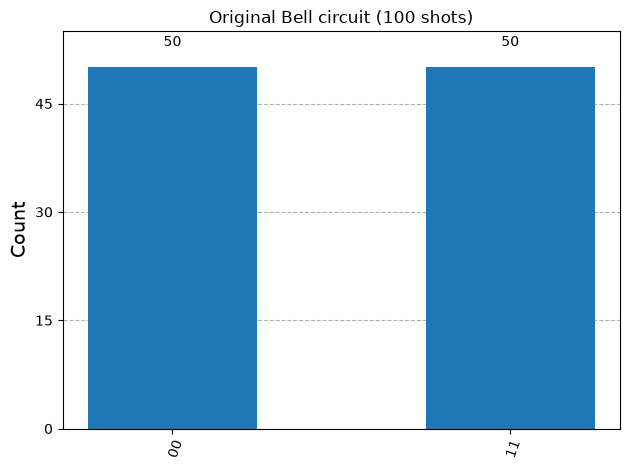

In [4]:
plot_histogram(counts_orig, title="Original Bell circuit (100 shots)")

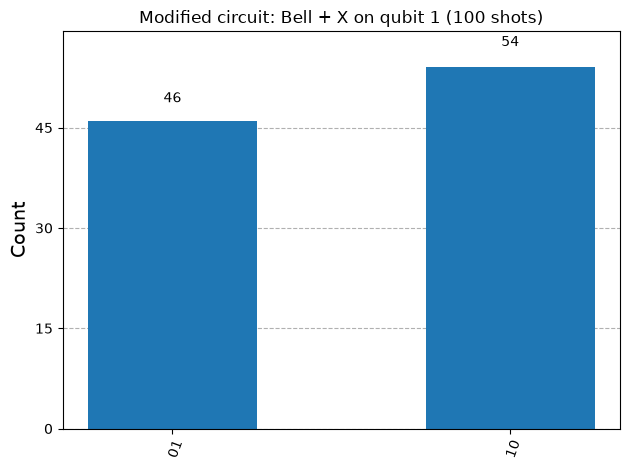

In [5]:
plot_histogram(counts_mod, title="Modified circuit: Bell + X on qubit 1 (100 shots)")

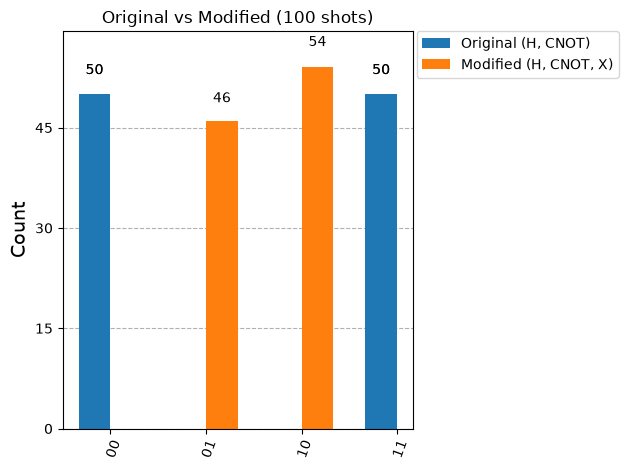

In [6]:
plot_histogram([counts_orig, counts_mod],
               legend=["Original (H, CNOT)", "Modified (H, CNOT, X)"],
               title="Original vs Modified (100 shots)")

In [7]:
print("COMPARISON: PREDICTIONS vs ACTUAL RESULTS")
print("-" * 60)
print(f"Original | Predicted: ~50% '00', ~50% '11' | Actual: {counts_orig}")
print(f"Modified | Predicted: ~50% '01', ~50% '10' | Actual: {counts_mod}")

print("\nExplanation of the observed change:")
print("The H gate puts qubit 0 in superposition, and the CNOT entangles the two qubits,")
print("giving the Bell state (|00> + |11>)/sqrt(2). The qubits are perfectly correlated,")
print("so only '00' and '11' appear, each about 50% of the time.")
print("Adding an X gate on qubit 1 flips its value in every outcome, so the state becomes")
print("(|01> + |10>)/sqrt(2). The qubits are still entangled and perfectly correlated,")
print("but now in the opposite way: they always give different results.")
print("Only '01' and '10' appear, each about 50% of the time, and '00' and '11' disappear.")

COMPARISON: PREDICTIONS vs ACTUAL RESULTS
------------------------------------------------------------
Original | Predicted: ~50% '00', ~50% '11' | Actual: {'11': 50, '00': 50}
Modified | Predicted: ~50% '01', ~50% '10' | Actual: {'01': 46, '10': 54}

Explanation of the observed change:
The H gate puts qubit 0 in superposition, and the CNOT entangles the two qubits,
giving the Bell state (|00> + |11>)/sqrt(2). The qubits are perfectly correlated,
so only '00' and '11' appear, each about 50% of the time.
Adding an X gate on qubit 1 flips its value in every outcome, so the state becomes
(|01> + |10>)/sqrt(2). The qubits are still entangled and perfectly correlated,
but now in the opposite way: they always give different results.
Only '01' and '10' appear, each about 50% of the time, and '00' and '11' disappear.
